# YSB Inventory and Supply Chain Analysis

**Context.** This analysis was done during my time as a Data Analyst at Genesis Accelerator. A startup in the program was building a product that connects a company's operational systems and generates insights from them. To evaluate that product, I was asked to analyse the same data from YSB, an Israeli infrastructure contractor, independently, so the startup's output could be compared against a manual baseline.

**Data.** Exports from YSB's ERP covering January to early June 2025, published with the company's permission.

**Questions**

1. How is inventory value distributed, and how much of it is idle?
2. Which items are heading for a shortage or a surplus once stock on hand is taken into account?
3. Which items combine high value with unstable demand (ABC-XYZ)?
4. How long do suppliers actually take to deliver, and how consistent are they?
5. Which items are ordered together, and in what ratio?
6. What can this data not answer, and what is needed to go further?

In [1]:
import warnings, itertools
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from bidi.algorithm import get_display  # renders Hebrew labels right-to-left in charts

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)

DATA = Path("../data")
FIG = Path("../images"); FIG.mkdir(exist_ok=True)
OUT = Path("../outputs"); OUT.mkdir(exist_ok=True)

BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})
he = lambda s: get_display(str(s))
ils = mtick.FuncFormatter(lambda v, _: f"₪{v/1e6:.1f}M" if abs(v) >= 1e6 else f"₪{v/1e3:.0f}K")

## 1. Load and prepare the data

All five sources are loaded once, column names are translated to English, and dates and numbers are parsed. Item codes are kept as text so that codes such as `A12000113` are not lost.

In [2]:
def to_num(s):
    """Strip currency symbols and thousands separators, then convert to float."""
    return pd.to_numeric(s.astype(str).str.replace(r"[^\d.\-]", "", regex=True), errors="coerce")

def to_date(s):
    return pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")

# Customer orders (demand)
co = pd.read_csv(DATA / "customer_orders_2025.csv", low_memory=False).rename(columns={
    "הזמנה": "order_id", "תאריך": "date", "סטטוס הזמנה": "status", "שם לקוח": "customer",
    'מק"ט': "item", "תאור מוצר": "description", "כמות": "qty", 'סה"כ ב-ש"ח': "value_ils", "פרויקט": "project"})
co["date"], co["item"] = to_date(co["date"]), co["item"].astype(str)

# Supplier purchase orders and goods receipts (supply)
po = pd.read_csv(DATA / "supplier_orders_2025.csv").rename(columns={
    "מס' ספק": "supplier_id", "שם ספק": "supplier", "הזמנה": "po_id", "תאריך": "po_date", "מק'ט": "item",
    "תאור מוצר": "description", "ת. אספקה": "requested_date", "כמות": "qty", "מחיר סופי בשקלים": "value_ils"})
po["po_date"], po["requested_date"], po["item"] = to_date(po["po_date"]), to_date(po["requested_date"]), po["item"].astype(str)

gr = pd.read_csv(DATA / "supplier_goods_receipts_2025.csv").rename(columns={
    "תאריך": "date", "מק'ט": "item", "תאור מוצר": "description", "כמות": "qty", "הזמנה": "po_id", "שם ספק": "supplier"})
gr["date"], gr["item"] = to_date(gr["date"]), gr["item"].astype(str)

# Inventory movements (two exports, combined into one table)
mv = pd.concat([pd.read_csv(DATA / f, low_memory=False) for f in
                ["inventory_movements_jan_apr_2025.csv", "inventory_movements_apr_on_2025.csv"]], ignore_index=True)
mv = mv.rename(columns={"תאריך": "date", "סוג תנועת מלאי": "movement_type", 'מק"ט': "item",
                        "כמות (קניה/מכירה)": "qty", 'עלות ש"ח': "cost_ils", "עלות ש\"ח ליח' ק/מ": "unit_cost_ils"})
mv["date"], mv["item"] = to_date(mv["date"]), mv["item"].astype(str)
mv["cost_ils"], mv["unit_cost_ils"] = to_num(mv["cost_ils"]), to_num(mv["unit_cost_ils"])

# Year-end inventory valuation (opening stock for 2025)
iv = pd.read_csv(DATA / "inventory_valuation_2024_12_31.csv").rename(columns={
    "קוד פריט": "item", "תיאור פריט": "description", "מחיר אחרון שחושב": "unit_cost_ils", "כמות": "qty", "ערך מלאי": "value_ils"})
iv["item"], iv["qty"] = iv["item"].astype(str), to_num(iv["qty"])
iv = iv[["item", "description", "unit_cost_ils", "qty", "value_ils"]]

DESC = pd.concat([iv.set_index("item")["description"], co.drop_duplicates("item").set_index("item")["description"]])
DESC = DESC[~DESC.index.duplicated()]

coverage = pd.DataFrame({
    "rows": [len(co), len(po), len(gr), len(mv), len(iv)],
    "from": [co.date.min(), po.po_date.min(), gr.date.min(), mv.date.min(), pd.Timestamp("2024-12-31")],
    "to":   [co.date.max(), po.po_date.max(), gr.date.max(), mv.date.max(), pd.Timestamp("2024-12-31")],
}, index=["Customer orders", "Supplier orders", "Goods receipts", "Inventory movements", "Inventory valuation"])
coverage["from"], coverage["to"] = coverage["from"].dt.date, coverage["to"].dt.date
coverage

,rows,from,to
Customer orders,7279,2025-01-01,2025-06-08
Supplier orders,1977,2025-01-01,2025-05-30
Goods receipts,1532,2025-01-01,2025-05-29
Inventory movements,13756,2025-01-02,2025-05-31
Inventory valuation,8186,2024-12-31,2024-12-31


## 2. Data quality checks

Three facts here shape the rest of the analysis:

- **Cancelled, rejected and draft order lines are excluded** from demand. Counting them would inflate demand for some items.
- **Only 62% of supplier order lines have a matching goods receipt.** The rest are either still open or are services and direct deliveries that never pass through the warehouse. Lead times are therefore measured only on received lines.
- **The requested delivery date equals the order date in 92% of lines.** The field is not used in practice, so on-time delivery against a promised date cannot be measured. Lead time is measured as days from purchase order to first receipt instead.

In [3]:
EXCLUDED = ["מבוטלת", "נדחה", "טיוטא"]   # cancelled, rejected, draft
demand = co[~co.status.isin(EXCLUDED)].copy()

po_received = po.merge(gr.groupby(["po_id", "item"]).date.min().rename("receipt_date"),
                       left_on=["po_id", "item"], right_index=True, how="left")

checks = pd.Series({
    "Customer order lines": len(co),
    "Lines excluded (cancelled / rejected / draft)": len(co) - len(demand),
    "Order lines with zero value": f"{(demand.value_ils == 0).mean():.0%}",
    "Supplier order lines": len(po),
    "Supplier order lines with a matching receipt": f"{po_received.receipt_date.notna().mean():.0%}",
    "Requested delivery date equal to order date": f"{(po.requested_date == po.po_date).mean():.0%}",
    "Movement types": mv.movement_type.nunique(),
})
checks.to_frame("value")

,value
Customer order lines,7279
Lines excluded (cancelled / rejected / draft),391
Order lines with zero value,17%
Supplier order lines,1977
Supplier order lines with a matching receipt,62%
Requested delivery date equal to order date,92%
Movement types,8


## 3. Where the inventory value sits (ABC by stock value)

Items are ranked by their value on 31 December 2024 and split into A (first 80% of value), B (next 15%) and C (last 5%).

Items in stock: 2,374 of 8,186 catalogue items | total value: ₪10,704,047


,items,value_ils,share_of_items,share_of_value
abc_value,,,,
A,154,"₪8,557,373",6.5%,79.9%
B,482,"₪1,610,873",20.3%,15.0%
C,1738,"₪535,801",73.2%,5.0%


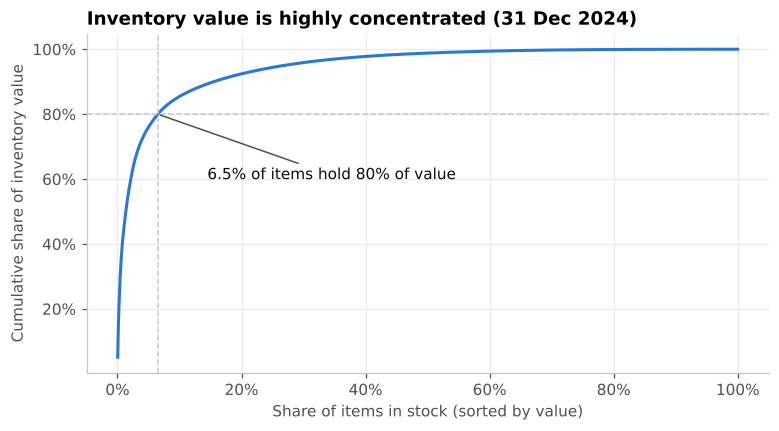

In [4]:
stock = iv[iv.value_ils > 0].sort_values("value_ils", ascending=False).reset_index(drop=True)
total_value = stock.value_ils.sum()
stock["cum_share"] = stock.value_ils.cumsum() / total_value
stock["abc_value"] = np.select([stock.cum_share <= 0.80, stock.cum_share <= 0.95], ["A", "B"], "C")

abc_summary = (stock.groupby("abc_value")
               .agg(items=("item", "size"), value_ils=("value_ils", "sum"))
               .assign(share_of_items=lambda d: d["items"] / d["items"].sum(),
                       share_of_value=lambda d: d.value_ils / total_value))
print(f"Items in stock: {len(stock):,} of {len(iv):,} catalogue items | total value: ₪{total_value:,.0f}")
display(abc_summary.style.format({"value_ils": "₪{:,.0f}", "share_of_items": "{:.1%}", "share_of_value": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, len(stock) + 1) / len(stock)
ax.plot(x, stock.cum_share, color=BLUE, lw=2)
a_cut = (stock.abc_value == "A").sum() / len(stock)
ax.axvline(a_cut, color=GREY, lw=1, ls="--"); ax.axhline(0.8, color=GREY, lw=1, ls="--")
ax.annotate(f"{a_cut:.1%} of items hold 80% of value", (a_cut, 0.8), xytext=(a_cut + 0.08, 0.6),
            color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(xlabel="Share of items in stock (sorted by value)", ylabel="Cumulative share of inventory value",
       title="Inventory value is highly concentrated (31 Dec 2024)")
fig.savefig(FIG / "01_inventory_value_pareto.png"); plt.show()

## 4. Idle stock and write-offs

An item in stock with no customer demand in five months is a candidate for idle stock. Because items can also be moved to project sites without a customer order, the check is done twice: no demand, and no movement of any kind.

**Reading.** About 28% of stock value (₪3.0M) had no customer order in January to May 2025, but almost all of it did move, mostly as transfers between warehouses and project sites. Truly idle stock is small, about ₪58K across 14 items. The ₪3.0M is still worth a review with the warehouse team: transfers without a customer order may hide stock that is sitting at project sites rather than being consumed.

In [5]:
demand_items = set(demand["item"])
moved_items = set(mv["item"])
stock["has_demand"] = stock["item"].isin(demand_items)
stock["has_movement"] = stock["item"].isin(moved_items)

no_demand = stock[~stock.has_demand]
idle = stock[~stock.has_demand & ~stock.has_movement]
writeoffs = mv[mv.movement_type == "השמדות מלאי"]

print(f"Stock with no customer demand Jan-May 2025: {len(no_demand):,} items, ₪{no_demand.value_ils.sum():,.0f} "
      f"({no_demand.value_ils.sum()/total_value:.0%} of value)")
print(f"Of these, with no movement of any kind:     {len(idle):,} items, ₪{idle.value_ils.sum():,.0f}")
print(f"Inventory write-offs Jan-May 2025:          {len(writeoffs):,} lines, ₪{writeoffs.cost_ils.sum():,.0f}")

top_no_demand = (no_demand.head(10)[["item", "description", "qty", "value_ils", "abc_value", "has_movement"]]
                 .style.format({"value_ils": "₪{:,.0f}", "qty": "{:,.0f}"}))
top_no_demand

Stock with no customer demand Jan-May 2025: 1,698 items, ₪3,035,539 (28% of value)
Of these, with no movement of any kind:     14 items, ₪57,935
Inventory write-offs Jan-May 2025:          625 lines, ₪51,883


,item,description,qty,value_ils,abc_value,has_movement
0,22001333,בולרד 4K OAK 800.4 LIGHT-Stainess Steel 316 P970094 10302,28,"₪545,958",A,True
3,32000026,גלאי העדפה IVRG1M-700251,100,"₪300,208",A,True
18,12000150,פנל מואר למעבר חציה 8X120 ס''מ אדום/ירוק,184,"₪101,200",A,True
37,22002397,"מכונת תשלום סגנון גט""י AW GP4M stand-alone automatic pay station",2,"₪60,911",A,True
46,11000107,EC2 CPU CF 3522 704 24710,11,"₪50,832",A,True
48,22002729,KIT STEM 275 H800 K4 - INOZ 316L-SV I300278 50001,6,"₪48,057",A,True
51,22000181,מדפסת VKP80II רשת,20,"₪45,140",A,True
55,11000137,ASSY XIO16 3522 704 73540 (כרטיס IO),39,"₪41,999",A,True
67,22002416,COMPLETE GEARMOTOR Xtreme 35 220V I271567 60001,11,"₪31,568",A,True
70,16000217,קופסאת לחצן אלומ' להולך רגל קומלפלט,156,"₪29,640",A,True


## 5. Shortages and surpluses, counting stock on hand

A simple comparison of receipts against customer demand ignores the stock that was already on the shelf. Here the projected balance adds the opening stock from the year-end valuation:

**projected balance = opening stock + goods received − customer demand**

**Reading.** The simple gap flags 733 items as short, but 372 of them were already covered by stock on hand. That leaves 361 items with a real projected shortage, led by cables (`17000172`, `17000010`, `17000006`, `17000028`) and terminal clamps (`25001111`). On the surplus side, the picture is worse than a simple gap suggests: item `30000035` (flat washers) looks like an 8,730-unit surplus from receipts alone, but with 29,310 units already in stock, the projected surplus is 38,040 units, about 30 times the five-month demand. The top surplus items are all low-cost fasteners, so the cash impact is limited, but the pattern points to ordering in fixed bulk quantities regardless of stock.

Items with demand: 1,091
Shortage by simple gap (receipts < demand): 733
Shortage after counting opening stock:      361
Simple-gap 'shortages' already covered by stock on hand: 372


,description,opening_stock,received,customer_demand,simple_gap,projected_balance
item,,,,,,
17000172,כבל CAT-7,1560.0,0.0,5550.0,-5550.0,-3990.0
25001111,מהדק WDU6-10,2003.0,0.0,5966.0,-5966.0,-3963.0
17000010,14X1.5+1X2.5+1X4 כבל,3400.0,5486.0,12221.0,-6735.0,-3335.0
17000006,כבל 3X1.5 N2XY,0.0,4500.0,7655.0,-3155.0,-3155.0
17000028,כבל 5X1.5 XLPE,3500.0,5000.0,11231.0,-6231.0,-2731.0
17000079,כבל הארקה 25 ממ' צ/' קשיח (בתוף 500 מ'),3450.0,5500.0,10280.0,-4780.0,-1330.0
17000011,8X1.5+1X2.5+1X4 כבל,2600.0,3500.0,7405.0,-3905.0,-1305.0
26001138,CISCO Identity Service Engine Subscription ISE-SEC-SUB,0.0,0.0,900.0,-900.0,-900.0
17000212,סיב אופטי 24 S.M משוריין עם ג'ל LDB-9-04X06-DKPRP-DKPRP-GG,0.0,4500.0,5300.0,-800.0,-800.0


,description,opening_stock,received,customer_demand,simple_gap,projected_balance
item,,,,,,
30000035,דסקית שטוחה 5/16X1.2X25,29310.0,10000.0,1270.0,8730.0,38040.0
30000030,אום משושה 5/16 BSW,19042.0,5000.0,1470.0,3530.0,22572.0
30000018,בורג ראש קודח 8X1/2 שחור,19081.0,1000.0,2500.0,-1500.0,17581.0
19000080,בורג הדוק מצופה 5/16X50,14845.0,0.0,300.0,-300.0,14545.0
30000009,בורג הדוק 5/16X30,14491.0,0.0,670.0,-670.0,13821.0


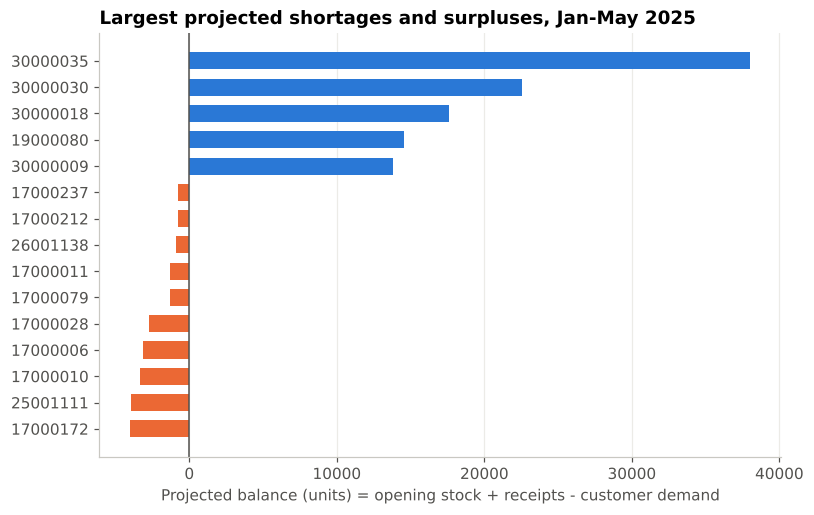

In [6]:
opening = iv.groupby("item").qty.sum()
received = gr.groupby("item").qty.sum()
ordered = demand.groupby("item").qty.sum()

balance = (pd.concat([opening.rename("opening_stock"), received.rename("received"), ordered.rename("customer_demand")], axis=1)
           .fillna(0).query("customer_demand > 0"))
balance["simple_gap"] = balance.received - balance.customer_demand           # supply minus demand only
balance["projected_balance"] = balance.opening_stock + balance.simple_gap    # adds the stock already on hand
balance["description"] = balance.index.map(DESC)

shortage = balance[balance.projected_balance < 0]
false_alarm = balance[(balance.simple_gap < 0) & (balance.projected_balance >= 0)]
print(f"Items with demand: {len(balance):,}")
print(f"Shortage by simple gap (receipts < demand): {(balance.simple_gap < 0).sum():,}")
print(f"Shortage after counting opening stock:      {len(shortage):,}")
print(f"Simple-gap 'shortages' already covered by stock on hand: {len(false_alarm):,}")

cols = ["description", "opening_stock", "received", "customer_demand", "simple_gap", "projected_balance"]
display(balance.sort_values("projected_balance").head(10)[cols])
display(balance.sort_values("projected_balance", ascending=False).head(5)[cols])

top = pd.concat([balance.nsmallest(10, "projected_balance"), balance.nlargest(5, "projected_balance")]).sort_values("projected_balance")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.projected_balance, color=np.where(top.projected_balance < 0, ORANGE, BLUE), height=0.65)
ax.axvline(0, color=MUTED, lw=1)
ax.set(xlabel="Projected balance (units) = opening stock + receipts - customer demand",
       title="Largest projected shortages and surpluses, Jan-May 2025")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "02_projected_stock_balance.png"); plt.show()

balance.sort_values("projected_balance").to_csv(OUT / "projected_stock_balance.csv", encoding="utf-8-sig")

## 6. ABC-XYZ: value against demand stability

Each item with demand gets two labels:

- **ABC by consumption value**: units demanded × unit cost, split 80% / 15% / 5%.
- **XYZ by demand stability**: the coefficient of variation (CV) of monthly demand. X: CV ≤ 0.5 (stable), Y: 0.5 to 1.0 (variable), Z: above 1.0 (erratic).

Only the five full months (January to May) are used.

**Reading.** Of the 65 A items, 50 have variable or erratic demand, and together they account for 58% of consumption value. Only 15 A items are stable. This is typical of a project-driven business: expensive items are ordered for specific projects, not consumed at a steady rate. For these items, safety stock based on average demand would either tie up cash or still miss peaks. They are better planned against the project schedule. The 567 C-Z items are the opposite case: low value and erratic, so simple reorder rules or ordering on demand are enough.

Items classified: 943 (items with demand and a known unit cost)


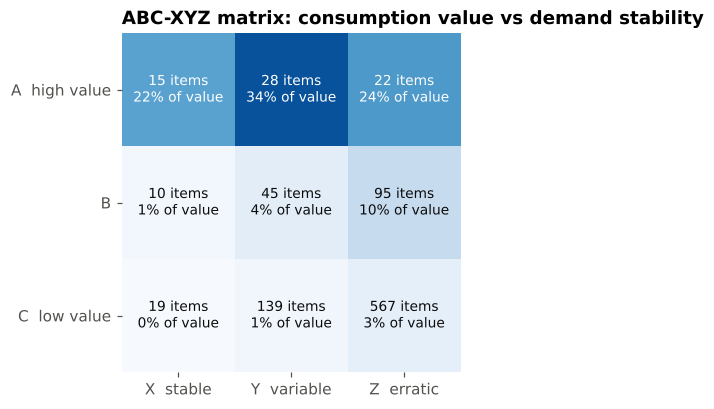

,description,units,months_with_demand,consumption_value_ils
item,,,,
16081977,PTZ NDP-5512-Z30L,323,4,"₪302,955"
16000274,ארון סולארי CO-SOL-B-150W-48H,13,3,"₪265,611"
22002891,ספק כח PLANET IPOE-171-95W כולל כבל מתח,193,4,"₪166,462"
22002894,TCP MODULE ADAM 6060,193,4,"₪166,215"
22002450,מחסום 6 מ' N&D 36 XTREME RAL 9006 P940093 10102,22,4,"₪140,377"
26001111,רישיון תוכנת ניהול וידאו לערוץ סעיף 3.3,300,1,"₪133,440"
25001354,ספק כח DRS-240-12,193,4,"₪132,715"
26001104,ראוטר תעשייתי RUTX50,63,4,"₪98,707"


In [7]:
# Consumption value = units demanded x unit cost (year-end cost, else median movement cost)
unit_cost = iv.set_index("item").unit_cost_ils
unit_cost = unit_cost[unit_cost > 0].combine_first(mv[mv.unit_cost_ils > 0].groupby("item").unit_cost_ils.median())

full_months = demand[demand.date < "2025-06-01"]          # June has only a few days of data
monthly = full_months.pivot_table(index="item", columns=full_months.date.dt.to_period("M"),
                                  values="qty", aggfunc="sum", fill_value=0)
cls = pd.DataFrame({"units": monthly.sum(axis=1),
                    "cv": monthly.std(axis=1, ddof=0) / monthly.mean(axis=1),
                    "months_with_demand": (monthly > 0).sum(axis=1)})
cls["unit_cost_ils"] = cls.index.map(unit_cost)
cls["consumption_value_ils"] = cls.units * cls.unit_cost_ils
cls = cls.dropna(subset=["consumption_value_ils"]).sort_values("consumption_value_ils", ascending=False)
cls["cum_share"] = cls.consumption_value_ils.cumsum() / cls.consumption_value_ils.sum()
cls["ABC"] = np.select([cls.cum_share <= 0.80, cls.cum_share <= 0.95], ["A", "B"], "C")
cls["XYZ"] = pd.cut(cls.cv, [-np.inf, 0.5, 1.0, np.inf], labels=["X", "Y", "Z"]).astype(str)
cls["description"] = cls.index.map(DESC)
print(f"Items classified: {len(cls):,} (items with demand and a known unit cost)")

counts = pd.crosstab(cls.ABC, cls.XYZ)
values = cls.pivot_table(index="ABC", columns="XYZ", values="consumption_value_ils", aggfunc="sum", fill_value=0)
share = values / values.values.sum()

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(share.values, cmap="Blues", vmin=0, vmax=share.values.max() * 1.15)
for i, r in enumerate(share.index):
    for j, c in enumerate(share.columns):
        dark = share.loc[r, c] > share.values.max() * 0.55
        ax.text(j, i, f"{counts.loc[r, c]} items\n{share.loc[r, c]:.0%} of value", ha="center", va="center",
                color="white" if dark else INK, fontsize=9)
ax.set_xticks(range(3), ["X  stable", "Y  variable", "Z  erratic"]); ax.set_yticks(range(3), ["A  high value", "B", "C  low value"])
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("ABC-XYZ matrix: consumption value vs demand stability")
fig.savefig(FIG / "03_abc_xyz_matrix.png"); plt.show()

cls.to_csv(OUT / "abc_xyz_classification.csv", encoding="utf-8-sig")
display(cls[(cls.ABC == "A") & (cls.XYZ == "Z")].head(8)[["description", "units", "months_with_demand", "consumption_value_ils"]]
        .style.format({"consumption_value_ils": "₪{:,.0f}", "units": "{:,.0f}"}))

## 7. Supplier lead times

Lead time is measured as days from the purchase order to the first goods receipt for that order line.

**Reading.** Half of all received lines arrive within 10 days, but the average is 19 days and one in ten lines takes 53 days or more. The spread matters more than the average. Some suppliers are fast and predictable (for example נ.חן חשמל and ג.ברס שיווק, with medians of 4 to 6 days and a narrow range). Others have a short median but a long tail. עופר שערים אוטומטיים has a median of 7.5 days but a 90th percentile of 54 days. For those suppliers, planning on the median will regularly cause delays. Concrete supplier טלאור בטון stands out with a median of about 75 days.

Order lines with a receipt: 1,228 | median lead time 10 days, mean 19, 90th percentile 53


,lines,median,mean,p90,std
supplier,,,,,
"טלאור בטון בע""מ",16,75.5,61.5,123.5,50.3
"בנדא מגנטיק בע""מ",23,34.0,31.0,48.0,16.3
"שיכון ובינוי סולל בונה-מנורה מערכות בע""מ",55,30.0,34.8,57.0,19.4
חגי ירון,87,18.0,22.2,36.0,15.7
"אוריאל שי בע""מ",28,17.0,15.5,27.0,9.3
"לדיקו בע""מ",21,13.0,24.1,61.0,23.9
"אדוויס אלקטרוניקה בע""מ",81,12.0,16.3,34.0,15.1
"שיר פלסט בע""מ",26,11.0,11.4,19.0,6.6
"עופר שערים אוטומטיים בע""מ",72,7.5,24.5,54.0,28.1


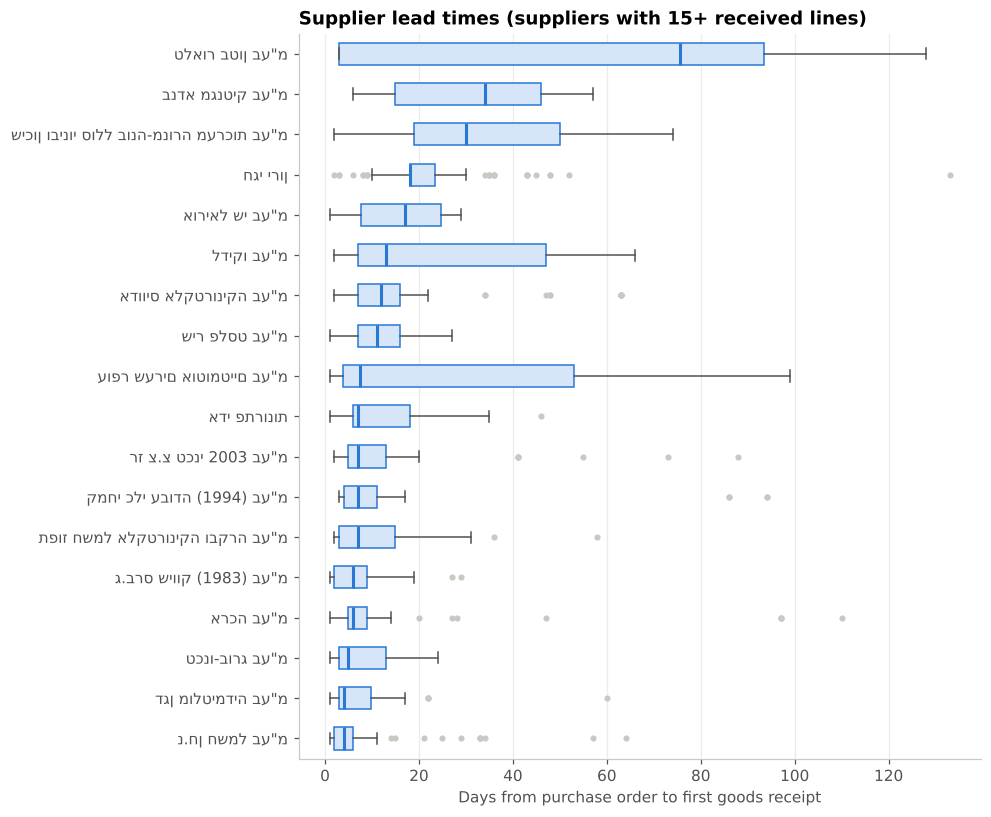

In [8]:
lt = po_received.dropna(subset=["receipt_date"]).copy()
lt["lead_time_days"] = (lt.receipt_date - lt.po_date).dt.days
lt = lt[lt.lead_time_days >= 0]
print(f"Order lines with a receipt: {len(lt):,} | median lead time {lt.lead_time_days.median():.0f} days, "
      f"mean {lt.lead_time_days.mean():.0f}, 90th percentile {lt.lead_time_days.quantile(.9):.0f}")

by_sup = (lt.groupby("supplier").lead_time_days
          .agg(lines="size", median="median", mean="mean", p90=lambda s: s.quantile(.9), std="std")
          .query("lines >= 15").sort_values("median", ascending=False))
display(by_sup.round(1))

order = by_sup.index[::-1]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(order) + 1))
ax.boxplot([lt.loc[lt.supplier == s, "lead_time_days"] for s in order], vert=False, widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#d6e6f8", edgecolor=BLUE), medianprops=dict(color=BLUE, lw=2),
           whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GREY, markeredgecolor=GREY))
ax.set_yticks(range(1, len(order) + 1), [he(s) for s in order])
ax.set(xlabel="Days from purchase order to first goods receipt",
       title="Supplier lead times (suppliers with 15+ received lines)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "04_supplier_lead_times.png"); plt.show()
by_sup.to_csv(OUT / "supplier_lead_times.csv", encoding="utf-8-sig")

## 8. Open purchase commitments

**Reading.** 38% of supplier order lines, worth about ₪9.8M, have no goods receipt in the data. The amount is highly concentrated: five lines, mostly traffic-system equipment from CAPSYS plus camera and communications equipment, account for 42% of it. These are likely large project orders with long delivery cycles, or deliveries that go directly to sites. Either way, they are commitments that should be tracked separately from regular stock purchases.

In [9]:
open_lines = po_received[po_received.receipt_date.isna()]
top5 = open_lines.nlargest(5, "value_ils")
print(f"Order lines with no receipt yet: {len(open_lines):,} ({len(open_lines)/len(po):.0%}), value ₪{open_lines.value_ils.sum():,.0f}")
print(f"Top 5 lines account for ₪{top5.value_ils.sum():,.0f} ({top5.value_ils.sum()/open_lines.value_ils.sum():.0%})")
top5[["supplier", "description", "qty", "value_ils", "po_date"]].style.format({"value_ils": "₪{:,.0f}"})

Order lines with no receipt yet: 749 (38%), value ₪9,836,072
Top 5 lines account for ₪4,141,240 (42%)


,supplier,description,qty,value_ils,po_date
1021,CAPSYS,0149VE-SGC-001 USIS,480,"₪1,243,677",2025-02-16 00:00:00
1022,CAPSYS,0149VE-SGE-001 MSAS,480,"₪1,170,225",2025-02-16 00:00:00
1193,"לדיקו בע""מ",PTZ NDP-5512-Z30L,200,"₪701,146",2025-04-15 00:00:00
1962,טלדור תקשורת ואבטחת,5G Sub-6 SA PIM P-5GS6-R16SA-GL,400,"₪515,559",2025-05-04 00:00:00
1025,CAPSYS,לולאת גלאי העדפה CAPSYS 3 מ 0149VE-WAB-001,408,"₪510,634",2025-02-16 00:00:00


## 9. Items ordered together

For every pair of items, the analysis counts how many customer orders contain both, and calculates three measures:

- **Confidence**: of the orders containing item A, the share that also contain item B.
- **Lift**: how much more often the pair appears than it would by chance. A lift of 25 means 25 times more often.
- **Quantity ratio**: the median number of units of B ordered per unit of A in the same order.

Large project orders with 20 or more items create many pairs at once, so the chart and table only keep pairs that also appear in at least 10 smaller orders.

**Reading.** Clear kits emerge. Terminal clamps `25001111` and side plates `25001110` are a clear example: 89% of orders with the clamps also include the plates, with a median of 14 clamps per plate. A barrier set, made of arm `22000222`, rubber kit `22000274` and light `22001026`, is ordered together almost every time in a 1 : 1 : 1 ratio. Two control cables (`17000009`, `17000010`) also travel together. These links matter for planning: if one item in a kit is short, the whole kit cannot be delivered. Several of the kit items are also on the projected shortage list in section 5 (`25001111`, `17000010`).

Orders: 1,223 | with 2+ items: 725 | pairs seen in 10+ orders: 2,522 | strong pairs (lift >= 10, confidence >= 70%): 1,836
Orders with 20+ items: 75 | strong pairs still seen in 10+ smaller orders: 15


,item_a,desc_a,item_b,desc_b,orders_together,orders_together_small,conf_a_to_b,conf_b_to_a,lift,median_qty_b_per_a
2224,25000275,מעצור למסילה 35 ES-35,25001110,דופן למהדק WDU2.5-10,40,13,50%,93%,14,0.5
2226,25001110,דופן למהדק WDU2.5-10,25001111,מהדק WDU6-10,33,15,77%,89%,25,14
1931,17000009,22X1.5+1X2.5+1X4 כבל,17000010,14X1.5+1X2.5+1X4 כבל,31,10,78%,82%,25,1
2225,25000275,מעצור למסילה 35 ES-35,25001111,מהדק WDU6-10,30,13,38%,81%,12,7.3
1940,25000153,מוט הארקה,25000315,רוכב מוט ארקה לכבל MU-1818-20,29,19,91%,100%,38,1
2148,17000006,כבל 3X1.5 N2XY,17000028,כבל 5X1.5 XLPE,26,13,79%,45%,17,0.75
1,22000274,"Kit – gom 3 מק""ט P120053 00001(גומי למחסום)",22001026,LIGHT 3 R/G P120077 00001,24,23,92%,96%,45,1
18,22000222,"BL-SMALL 30 מק""ט 323101(זרוע 3 מ')",22001026,LIGHT 3 R/G P120077 00001,23,22,100%,92%,49,1
17,22000222,"BL-SMALL 30 מק""ט 323101(זרוע 3 מ')",22000274,"Kit – gom 3 מק""ט P120053 00001(גומי למחסום)",23,22,100%,88%,47,1
2196,13000005,(שלט ללחצן ה.רגל א44-(חד צדדי,13000019,שלט ללחצן ה.רגל א44-(דו צדדי),21,13,91%,66%,35,1


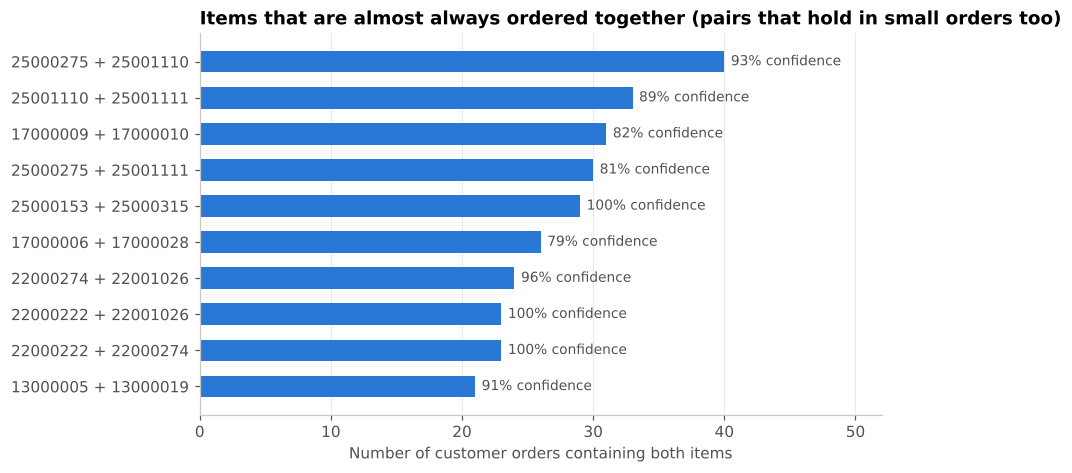

In [10]:
baskets = demand.groupby("order_id")["item"].apply(lambda s: sorted(set(s)))
n_orders = len(baskets)
item_count = Counter(i for b in baskets for i in b)
pair_count = Counter(p for b in baskets if len(b) > 1 for p in itertools.combinations(b, 2))
qty = demand.groupby(["order_id", "item"]).qty.sum()

rows = []
for (a, b), n in pair_count.items():
    if n < 10:
        continue
    both = baskets[baskets.apply(lambda s: a in s and b in s)].index
    ratio = (qty.loc[list(zip(both, [b] * len(both)))].values / qty.loc[list(zip(both, [a] * len(both)))].replace(0, np.nan).values)
    rows.append({"item_a": a, "item_b": b, "orders_together": n,
                 "conf_a_to_b": n / item_count[a], "conf_b_to_a": n / item_count[b],
                 "lift": n * n_orders / (item_count[a] * item_count[b]),
                 "median_qty_b_per_a": np.nanmedian(ratio)})
pairs = pd.DataFrame(rows).sort_values(["orders_together", "lift"], ascending=False)
pairs["desc_a"], pairs["desc_b"] = pairs.item_a.map(DESC), pairs.item_b.map(DESC)
strong = pairs[(pairs.lift >= 10) & (pairs[["conf_a_to_b", "conf_b_to_a"]].max(axis=1) >= 0.7)]
print(f"Orders: {n_orders:,} | with 2+ items: {sum(len(b) > 1 for b in baskets):,} | pairs seen in 10+ orders: {len(pairs):,} "
      f"| strong pairs (lift >= 10, confidence >= 70%): {len(strong):,}")
# Robustness: large project orders (20+ items) create many pairs at once. Recount pairs on smaller orders only.
small = baskets[baskets.str.len() < 20]
small_count = Counter(p for b in small if len(b) > 1 for p in itertools.combinations(b, 2))
strong = strong.assign(orders_together_small=[small_count.get((a, b), 0) for a, b in zip(strong.item_a, strong.item_b)])
print(f"Orders with 20+ items: {(baskets.str.len() >= 20).sum()} | strong pairs still seen in 10+ smaller orders: "
      f"{(strong.orders_together_small >= 10).sum():,}")
pairs.to_csv(OUT / "items_ordered_together.csv", index=False, encoding="utf-8-sig")
robust = strong[strong.orders_together_small >= 10]
display(robust.head(12)[["item_a", "desc_a", "item_b", "desc_b", "orders_together", "orders_together_small", "conf_a_to_b", "conf_b_to_a", "lift", "median_qty_b_per_a"]]
        .style.format({"conf_a_to_b": "{:.0%}", "conf_b_to_a": "{:.0%}", "lift": "{:.0f}", "median_qty_b_per_a": "{:.2g}"}))

show = robust.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f"{a} + {b}" for a, b in zip(show.item_a, show.item_b)]
ax.barh(labels, show.orders_together, color=BLUE, height=0.6)
for y, (n, c) in enumerate(zip(show.orders_together, show[["conf_a_to_b", "conf_b_to_a"]].max(axis=1))):
    ax.text(n + 0.5, y, f"{c:.0%} confidence", va="center", color=MUTED, fontsize=9)
ax.set(xlabel="Number of customer orders containing both items", title="Items that are almost always ordered together (pairs that hold in small orders too)")
ax.grid(axis="y", visible=False); ax.set_xlim(0, show.orders_together.max() * 1.3)
fig.savefig(FIG / "05_items_ordered_together.png"); plt.show()

## 10. Data limitations and what is needed next

The analysis explains what the current data can explain. Going further needs information that is not in these exports:

| Missing information | Why it matters | What to request from YSB |
|---|---|---|
| Holding cost per item (storage, capital, handling) | Weighs the cost of keeping an item against its importance, beyond its purchase price | Warehouse cost allocation or a standard holding-cost rate |
| Item criticality | A cheap item that stops a project matters more than an expensive optional one | A criticality flag per item or category, from the project managers |
| Bills of materials and standard kits | Section 9 infers kits from orders. The real kit definitions would make planning exact | Kit or BOM definitions from the ERP |
| Promised delivery dates | The requested date field is unused, so supplier on-time performance cannot be measured | Agreed delivery dates per order line |
| Actual consumption at project sites | Transfers to sites are not the same as consumption, so idle stock may be hidden there | Site consumption reports or stock counts per site |
| A longer history | Five months is too short for seasonality or reliable demand forecasts | 12 to 24 months of the same exports |

## Comparison with the startup's product

My role ended with this baseline and the list of data requirements above. The comparison with the startup's product output was carried out by the startup and the accelerator team.

## 11. Summary of findings

| # | Finding | Number | Recommendation |
|---|---|---|---|
| 1 | Inventory value is concentrated | 6.5% of items hold 80% of the ₪10.7M stock value | Focus counting, review and reorder effort on the 154 A items |
| 2 | Truly idle stock is small, but much stock moves without a customer order | ₪58K idle; ₪3.0M (28%) with no customer demand | Review the ₪3.0M with the warehouse team and check stock at project sites |
| 3 | Half of the simple-gap "shortages" are covered by stock on hand | 733 flagged, 361 real | Always include opening stock in shortage reports |
| 4 | Surpluses are concentrated in bulk-ordered fasteners | Item 30000035: projected surplus of 38,040 units, about 30× the five-month demand | Replace fixed bulk orders with reorder points |
| 5 | High-value items have unstable demand | 50 of 65 A items are Y or Z, 58% of consumption value | Plan A-Y and A-Z items against project schedules, not average demand |
| 6 | Lead times have long tails | Median 10 days, 90th percentile 53 days | Plan on the 90th percentile for long-tail suppliers; start recording promised dates |
| 7 | Clear product kits exist | e.g. 89% of clamp orders include side plates, at 14 clamps per plate; a 1 : 1 : 1 barrier set | Define kits in the ERP and plan kit items together |
| 8 | Open commitments are large and concentrated | ₪9.8M open; top 5 lines = 42% | Track large project orders separately from regular purchasing |

Detailed tables are saved in [`outputs/`](../outputs) and charts in [`images/`](../images).